# 03 — Minimal FdeR model: TF RBS shifts EC50

**Status: mechanistic *illustration*, not a calibration, historical design-run reconstruction or the VBMC 11D model.**

This notebook follows the style of the supplied `Simulation_Gene_Expression_pyLab.ipynb`: define a small ODE function, list parameters and initial conditions, integrate with SciPy, sweep a genetic parameter, then plot dose-response and time courses.

The three states are **FdeR [nM]**, **intracellular naringenin [µM]**, **GFP [illustrative MEFL/cell]**. The extracellular naringenin dose and genetic RBS multipliers `qTF`, `qOUT` are **external inputs**, not states. Units of time: **minutes**.

It is specifically the *ligand-activated FdeR* core of the later mechanistic model, without the eventual additions `rho0_TF`, `gamma_TF`, `TFcapacity`, batch offsets `B1/B2`, or context-specific `cK2`.

## Equations

$$\frac{dR}{dt}=k_R q_{TF}-(d_R+\mu)R,\qquad
\frac{dI}{dt}=k_{in}(N_e-I)-(d_I+\mu)I$$

$$ f_N=\frac{I^n}{K_N^n+I^n},\quad
P_{fdeO}=\beta+(1-\beta)\frac{R f_N}{K_P+R f_N} $$

$$\frac{dG}{dt}=k_G q_{OUT}P_{fdeO}-(d_G+\mu)G.$$

The code parameterizes $k_R$ using the reference R3 steady TF concentration, and $k_G$ using the reference GFP scale. These are illustrative, not fitted. The RBS ratios come from the independent biopart measurements. Note that *finite-dose operational EC50* in this teaching example is **not** the final paper Hill estimator.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'biosensor_pipeline').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print('Project root:', ROOT)


Project root: /workspaces/biosensor-python-pipeline


## 1. Define parameters and state derivative function

The reusable implementation is in `biosensor_pipeline/models/minimal_fder.py`. This is the same design pattern as the provided PyLab example, using the contemporary `solve_ivp` signature `f(t, state, ...)` rather than legacy `odeint(f, state0, t, ...)`.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from biosensor_pipeline.models.minimal_fder import (
    MinimalParameters, minimal_rhs, promoter_activity,
    simulate_minimal_one, simulate_minimal_dose_response, normalized_half_response)
p = MinimalParameters()
print('Reference TF at R3:', p.tf_R3_steady_nM, 'nM')
print('qTF (R4/R3):', p.q_tf('R4'))
print('GFP reporter scaling (R4/R3):', p.q_out('R4'))
print('PfdeO activity at zero naringenin:', promoter_activity(400, 0, p))

Reference TF at R3: 600.0 nM
qTF (R4/R3): 0.0336076817558299
GFP reporter scaling (R4/R3): 0.0336076817558299
PfdeO activity at zero naringenin: 0.003


## 2. Simulate three genetic architectures

The naming order is **TF RBS / reporter RBS**. Strong TF: R3 = B0034. Weak TF: R4 = J61100. R3R3 and R4R3 differ in *TF* translation; R4R3 and R4R4 differ in *reporter* translation.

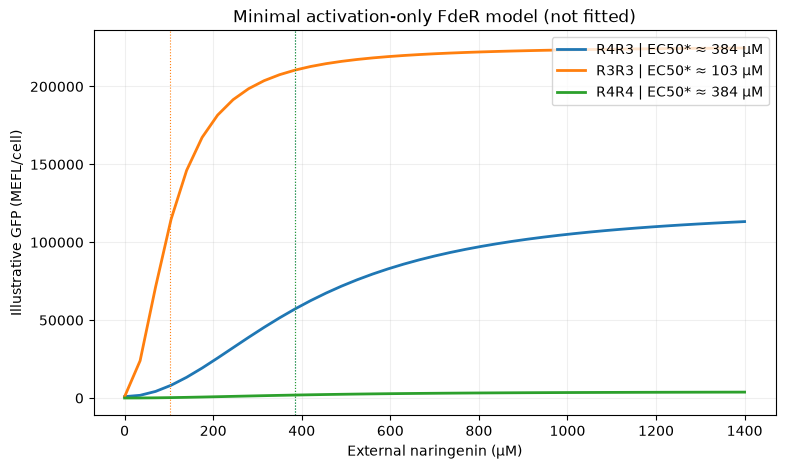

Construct | EC50* [µM] | Basal [MEFL/cell] | DR [MEFL/cell]
('R4R3', 384.1, np.float64(900.0), np.float64(112362.4))
('R3R3', 103.4, np.float64(900.0), np.float64(223798.8))
('R4R4', 384.1, np.float64(30.2), np.float64(3776.2))
* EC50 is a finite-range midpoint here, not the published Hill EC50.


In [3]:
doses = np.linspace(0, 1400, 41)
fig, ax = plt.subplots(figsize=(8.8, 5.0))
rows=[]
for name in ('R4R3','R3R3','R4R4'):
    x,y = simulate_minimal_dose_response(doses,name[:2],name[2:],p)
    e = normalized_half_response(x,y)
    rows.append((name,round(e,1),round(y[0],1),round(np.ptp(y),1)))
    ax.plot(x,y,label=f'{name} | EC50* ≈ {e:.0f} µM',linewidth=2)
    ax.axvline(e,color=ax.lines[-1].get_color(),lw=.8,ls=':')
ax.set(xlabel='External naringenin (µM)',ylabel='Illustrative GFP (MEFL/cell)',
       title='Minimal activation-only FdeR model (not fitted)')
ax.legend(loc='upper right');ax.grid(alpha=.2)
plt.show()
print('Construct | EC50* [µM] | Basal [MEFL/cell] | DR [MEFL/cell]')
for row in rows:print(row)
print('* EC50 is a finite-range midpoint here, not the published Hill EC50.')

## 3. Time courses at the same inducer concentration

This confirms which state changes when the TF RBS changes, independently of the reporter RBS.

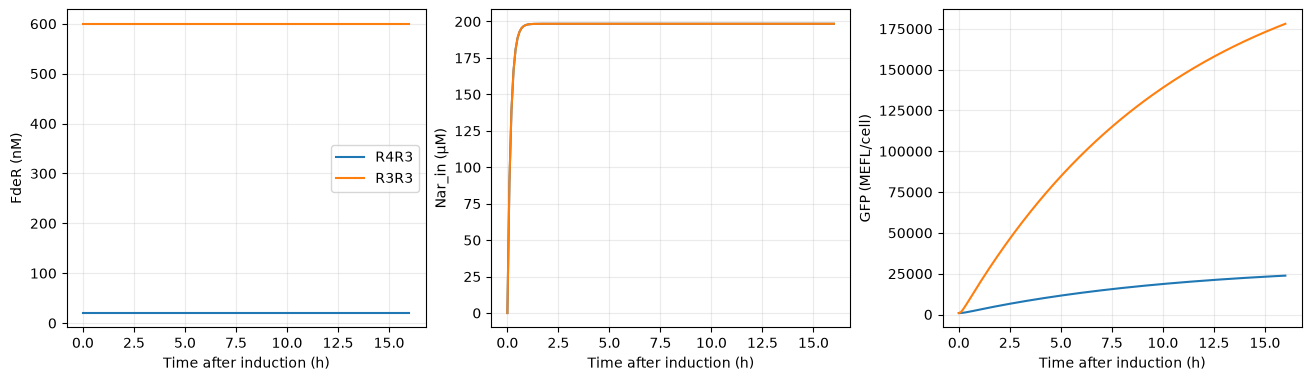

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.7), layout='constrained')
for name in ('R4R3','R3R3'):
    sol = simulate_minimal_one(200,tf_rbs=name[:2],out_rbs=name[2:],p=p)
    for i,ax in enumerate(axs):ax.plot(sol.t/60,sol.y[i],label=name)
for ax,label in zip(axs,['FdeR (nM)','Nar_in (µM)','GFP (MEFL/cell)']):
    ax.set(xlabel='Time after induction (h)',ylabel=label);ax.grid(alpha=.25)
axs[0].legend();plt.show()

## 4. What this model can and cannot explain

The stronger TF RBS **decreases the effective dose threshold** in this activating model. Weakening the reporter RBS **scales GFP output** without shifting the EC50. However, without additional mechanisms, the strong TF condition also has a greater inducible capacity; this is **opposite to the archived experimental DR trend**. The model is therefore **not a quantitative reproduction of both biosensors**.

For actual calibration, a private normalized experimental CSV must be supplied and the fit would need to be labelled as a *new minimal-model fit*, not the historical forecast. Do not place unpublished experiments in the public repository.

In [5]:
print('Next: 04_final_FdeR_MATLAB_port.ipynb for frozen 11D simulation; 05_historical_2025_candidate.ipynb for the distinct older de-repression law.')

Next: 04_final_FdeR_MATLAB_port.ipynb for frozen 11D simulation; 05_historical_2025_candidate.ipynb for the distinct older de-repression law.
